# Synthetic Data Generator

This notebook creates synthetic data (bank statements) as PDFs to be used with the financial analysis notebook.

## Import Packages

In [281]:
from fpdf import FPDF
from fpdf.fonts import FontFace
from fpdf.enums import TableSpan
from datetime import datetime
from math import ceil
import pdfplumber
import calendar
import ast
import os
import random

## Constants

In [282]:
dir_path = "..\\synthetic-data\\" # Path to retrieve data from
llm_files_path = "llm-files\\"
list_file = "synthetic_data_as_list.txt"
logo_file = "..\\images\\logos\\banking-logo.png"

## Load synthetic data that was generated with an LLM

In [284]:
all_transactions = [[[]]]
list_dir_path = f"{dir_path}{llm_files_path}{list_file}"

with open(list_dir_path, "r") as file:
    all_transactions = ast.literal_eval(file.read()) #read the text and evalutate the text to a 3D list

num_of_pdfs = len(all_transactions)
    
print(f"Number of statements imported: {num_of_pdfs}\n")

for count, tran in enumerate(all_transactions):
    print(f"Statement {count+1}: {len(tran)} transactions")

Number of statements imported: 48

Statement 1: 43 transactions
Statement 2: 47 transactions
Statement 3: 47 transactions
Statement 4: 44 transactions
Statement 5: 47 transactions
Statement 6: 48 transactions
Statement 7: 46 transactions
Statement 8: 47 transactions
Statement 9: 45 transactions
Statement 10: 51 transactions
Statement 11: 45 transactions
Statement 12: 45 transactions
Statement 13: 40 transactions
Statement 14: 45 transactions
Statement 15: 52 transactions
Statement 16: 46 transactions
Statement 17: 45 transactions
Statement 18: 46 transactions
Statement 19: 46 transactions
Statement 20: 50 transactions
Statement 21: 53 transactions
Statement 22: 49 transactions
Statement 23: 48 transactions
Statement 24: 48 transactions
Statement 25: 49 transactions
Statement 26: 53 transactions
Statement 27: 49 transactions
Statement 28: 48 transactions
Statement 29: 47 transactions
Statement 30: 41 transactions
Statement 31: 45 transactions
Statement 32: 50 transactions
Statement 33: 

In [285]:
all_transactions

[[['AUG02', 'EMPLOYER PAYROLL', '0.00', '3680.00', '10412.28', '2022'],
  ['AUG02', 'ESSO BLACK ROCK', '71.93', '0.00', '10340.35', '2022'],
  ['AUG06', 'NETFLIX*MONTHLY', '31.99', '0.00', '10308.36', '2022'],
  ['AUG06', '2.00% Exchange Tax', '0.64', '0.00', '10307.72', '2022'],
  ['AUG06', 'MAS STORES 1048', '141.96', '0.00', '10165.76', '2022'],
  ['AUG06', 'OISTINS FISH FRY', '70.47', '0.00', '10095.29', '2022'],
  ['AUG07', 'RENT PAYMENT', '1246.33', '0.00', '8848.96', '2022'],
  ['AUG07', 'BARBADOS LIGHT & POWER', '157.76', '0.00', '8691.20', '2022'],
  ['AUG08', 'TRIMART SUPERMARKET', '102.15', '0.00', '8589.05', '2022'],
  ['AUG08', 'SOL TOP ROCK 211788', '72.13', '0.00', '8516.92', '2022'],
  ['AUG08', 'CHEFETTE ROCKLEY', '78.95', '0.00', '8437.97', '2022'],
  ['AUG09', 'SURFERS BAY GYM', '94.46', '0.00', '8343.51', '2022'],
  ['AUG09', 'KFC BARBADOS 021 479557', '52.87', '0.00', '8290.64', '2022'],
  ['AUG12', 'FLOW INTERNET', '150.52', '0.00', '8140.12', '2022'],
  ['AUG12',

## Generate PDFs with synthetic data

Some PDFs in the original dataset had blank pages so the synthetic dataset will model this issue for two to six PDFs. The number of files is randomly chosen then which files in particular is also randomly chosen.

In [286]:
random_files_count = random.randint(2,6) # A random number to represent how many files will be altered
random_file_nums_list = [] # Holds the index for the random files that will be altered

for num in range(0, random_files_count):

    while True:
        random_file_num = random.randint(0, num_of_pdfs-1)

        if random_file_num not in random_file_nums_list: # Only allow unique index values
            random_file_nums_list.append(random_file_num)
            break
        else:
            print(f"Random number {random_file_num} already exists in list")

print("Random number files to alter:", random_files_count)
print("Index values from", num_of_pdfs, "PDFs:", random_file_nums_list)

Random number files to alter: 2
Index values from 48 PDFs: [42, 7]


In [287]:
starting_balance = 6732.28 # Balance Forward to use for first statement
heading_font_size = 14
heading_title = "STATEMENT OF ACCOUNT"
main_font_size = 9
footer_main_font_size = 8
font = "Helvetica"
light_grey_colour = "#e0e0e0"
closing_balance_prev_month = "" # Keeps track of Closing Balance from previous month to as Starting Balance in next month
line_spacing = 1.3 # Expands line spacing for Branch Name, Client's Name and Address, Currency and Statement Date areas

# The transactions for each month will be split into buckets of size 26 (26 transaction per bucket)
# This determines how many pages that the PDF will have
# This length also ensures that the footer table fits on the page
transactions_per_page = 26 

# Transaction Header will be prepended to the top of each transaction split
transactions_header = [["DATE", "DESCRIPTION", "DEBITS", "CREDITS", "BALANCE"]]

# Balance Forward will also be appended after Transaction Header for each transactions split
# <Date> and <BALANCE_AMOUNT> are placeholders that will be assigned later
balance_forward_row = [["<Date>", "BALANCE FORWARD", "0.00", "0.00", "<BALANCE_AMOUNT>"]]

# Branch Name, Client's Name and Address
branch_client_info = ["MAIN STREET BRANCH","JOHN DOE","PIE HILL","BARBADOS"]

# Additional client information
# <Page_#> is a placeholder that will be assigned later
account_details = [
                    ["Branch", "Account Number", "Page", "Tax ID"],
                    ["123", "111111", "<Page_#>", "123456"]
                ]

for doc_count, transactions in enumerate(all_transactions):

    transactions_year = transactions[0][-1] # Grab the year for this statement from the first transaction
    transactions = [data[:-1] for data in transactions] # Remove the year value from each transaction

    pdf = FPDF()
    pdf.b_margin = pdf.t_margin # Make bottom margin smaller so more can fit on each page
    required_num_pages = ceil(len(transactions)/transactions_per_page) # Calculate number of pages needed

    # These counting and summing variables fill the values for the THIS STATEMENT row in the footer table 
    # on the last page of the PDF
    debits_total_count = credits_total_count = 0
    debits_total_amount = credits_total_amount = 0.0

    starting_balance_statement = "" # Keeps track of the Starting Balance for the month
    statement_generation_timestamp = datetime.now().strftime("%d/%m/%Y %H:%M:%S")

    for required_page in range(0, required_num_pages):
        
        # Set the Page Number placeholder before writing the Account Details Table (first table in top right hand corner)
        account_details[1][2] = str(required_page+1) 

        pdf.add_page()

        pdf.image(logo_file, x=pdf.l_margin, y=pdf.t_margin, h=pdf.eph/15, keep_aspect_ratio=True)

        # Write Heading Title to PDF and right align (width of cell = 1/2 of page width)
        pdf.set_x(pdf.epw/2)
        pdf.set_font(font, "B", size=heading_font_size)
        pdf.ln(pdf.font_size)
        pdf.cell(0, 0, text=heading_title, align='RIGHT')
        pdf.ln()

        # Write current timestamp to represent when the bank statement was "generated"
        pdf.set_font(font, size=main_font_size)
        pdf.cell(0, 0, statement_generation_timestamp, align="RIGHT")
        pdf.ln()

        pdf.set_draw_color(light_grey_colour)

        # Write Account Details table
        with pdf.table(text_align=("CENTER", "CENTER", "CENTER", "CENTER"),
                    headings_style = FontFace(emphasis="BOLD", fill_color=light_grey_colour),
                    width=100,
                    col_widths=(1, 2, 1, 1),
                    align='RIGHT'
                    ) as account_details_table:
            for details in account_details:
                row = account_details_table.row()
                for detail in details:
                    row.cell(detail)

        pdf.ln(pdf.font_size*4)

        # If this page is the first page then write Branch Name, Client's Name and Address
        # This info is only present on the first page
        if required_page == 0:
            for info in branch_client_info:
                pdf.cell(40, pdf.font_size*1.3, info, align="LEFT")
                pdf.ln()

            pdf.ln(pdf.font_size*2)

        # Write Transactions table
        with pdf.table(col_widths=(1, 5, 2, 2, 2),
                    text_align=("LEFT", "LEFT", "RIGHT", "RIGHT", "RIGHT"),
                    headings_style = FontFace(emphasis="BOLD", fill_color=light_grey_colour)
                    ) as transactions_table:

            # Slice transactions to create the split for the current page
            transactions_split = transactions[required_page * transactions_per_page:(required_page + 1) * transactions_per_page]

            # Checks if the current page is the first page
            if required_page == 0:
                # If the current statement is the first statement then the Starting Balance is set to the initial value that is specified
                if doc_count == 0:
                    starting_balance_page = starting_balance

                # Else if the current statement is not the first statement then the Starting Balance is set using the value from the last day in the previous month
                else:
                    starting_balance_page = closing_balance_prev_month
                
                month = (transactions[0][0])[:3].title() # Get month from first transaction
                first_day = (transactions[0][0])[3:] # Get day from first transaction
                first_date_str = f"{first_day} {month} {transactions_year}"
                first_date = datetime.strptime(first_date_str, "%d %b %Y") # Create datetime object using stored day, month & year

                mth = first_date.month # Get integer representation of month from datetime object
                yr = first_date.year # Get year from datetime object

                # If month is not January then subtract one from month to get previous month and year remains unchanged
                if mth != 1:
                    prev_mth = mth-1 
                    prev_yr = yr

                # Else if month is January then set previous month to December and subtract one from year
                else:
                    prev_mth = 12
                    prev_yr = yr-1

                _, last_day = calendar.monthrange(prev_yr, prev_mth) # Store last day based on the calculated previous month & year

                # Create date for Balance Forward
                balance_forward_date_str = f"{last_day} {prev_mth} {prev_yr}"
                balance_forward_date = datetime.strptime(balance_forward_date_str , "%d %m %Y")
                balance_forward_date_fmt = balance_forward_date.strftime("%b%d").upper()

            # Else if current page is not the first page:
            # - Starting Balance is pulled from the last transaction from the previous split for this transaction month
            # - The Balance Forward date is taken from the first transaction of the current split
            else:
                starting_balance_page = transactions[((required_page * transactions_per_page) - 1)][4]
                balance_forward_date_fmt = transactions_split[0][0]

            # Set the <Date> and <BALANCE_AMOUNT> placeholders before writing the Transactions table (second table ion each page)
            balance_forward_row[0][0] =  balance_forward_date_fmt 
            balance_forward_row[0][4] =  str(starting_balance_page)

            # If the current page is the first page then store this Starting Balance to use in the final Footer Table
            if required_page == 0:
                starting_balance_statement = str(starting_balance_page)

            # Append the Transaction Header and Balance Forward Row to the Transactions split
            transactions_split_with_header = transactions_header + balance_forward_row + transactions_split

            _, last_day_current_statement = calendar.monthrange(yr, mth) # Store last day based on the calculated previous month & year

            last_date_current_statement_str = f"{last_day_current_statement} {mth} {yr}"
            last_date_current_statement = datetime.strptime(last_date_current_statement_str , "%d %m %Y")
            last_date_current_statement_fmt = last_date_current_statement.strftime("%Y-%m-%d")
            
            pdf.cell(0, pdf.font_size*1.3, "BARBADIAN DOLLAR", align="RIGHT")
            pdf.ln()
            pdf.cell(0, pdf.font_size*1.3, last_date_current_statement_fmt, align="RIGHT")
            pdf.ln(pdf.font_size*2)

            for transaction in transactions_split_with_header:
                row = transactions_table.row()
                for info in transaction:
                    row.cell(info)

        pdf.ln(pdf.font_size*2)

        # Store all Debit and Credit amounts for the transactions split in corresponding variables
        debits = [float(data[2]) for data in transactions_split_with_header[1:] if float(data[2]) > 0]
        credits = [float(data[3]) for data in transactions_split_with_header[1:] if float(data[3]) > 0]

        # Count and sum the Debits and Credits
        debits_count = len(debits)
        debits_amount = sum(debits)
        credits_count = len(credits)
        credits_amount = sum(credits)

        # Keep running totals for each count and sum
        debits_total_count += debits_count
        debits_total_amount += debits_amount 
        credits_total_count += credits_count
        credits_total_amount += credits_amount 

        footer_data = [
            ["", "STARTING BALANCE", "DEBITS", TableSpan.COL, "CREDITS", TableSpan.COL, "CLOSING BALANCE"],
            ["", TableSpan.ROW, "COUNT", "AMOUNT", "COUNT", "AMOUNT", TableSpan.ROW],
            ["THIS PAGE", str(starting_balance_page), str(debits_count), f"{debits_amount:.2f}", str(credits_count), f"{credits_amount:.2f}", transactions_split_with_header[-1][-1]]
        ]

        # If current page is the last page then add the THIS STATEMENT row to the Footer data array
        # Also, store the Closing Balance for this statement to use in the next statement
        if required_page == (required_num_pages-1):
            footer_data.append(["THIS STATEMENT", starting_balance_statement, str(debits_total_count), f"{debits_total_amount:.2f}", str(credits_total_count), f"{credits_total_amount:.2f}", transactions_split_with_header[-1][-1]])
            closing_balance_prev_month = transactions_split_with_header[-1][-1]

        pdf.set_font(font, size=footer_main_font_size)

        #Write Footer table 
        with pdf.table(col_widths=(2, 2, 1, 2, 1, 2, 2),
                    num_heading_rows=2,
                    text_align=("CENTER", "CENTER", "CENTER", "CENTER", "CENTER", "CENTER", "CENTER"),
                    headings_style = FontFace(emphasis="BOLD", fill_color=light_grey_colour)) as footer_table:
            for data_row in footer_data:
                row = footer_table.row()
                for info in data_row:
                    row.cell(info)

    mth_leading_zero = last_date_current_statement.strftime("%m")
    output_filename = f"{dir_path}statement_{mth_leading_zero}_{yr}.pdf"

    # Add a blank page as the last page if this file was randomly chosen
    if doc_count in random_file_nums_list:
        pdf.add_page()
        print('Blank page added to', output_filename)

    pdf.output(output_filename)

f'PDF generation completed'

Blank page added to ..\synthetic-data\statement_03_2023.pdf
Blank page added to ..\synthetic-data\statement_02_2026.pdf


'PDF generation completed'

## Preview PDFs

Quick run of pdfplumber to ensure that the generated PDFs can be read correctly for data extraction.

In [288]:
files = os.listdir(dir_path)
files = [file for file in files if file.find('.pdf') != -1] # Only keep filenames for PDFs
print("Number of files in directory:", len(files))
print("Files: ", files)

Number of files in directory: 48
Files:  ['statement_01_2023.pdf', 'statement_01_2024.pdf', 'statement_01_2025.pdf', 'statement_01_2026.pdf', 'statement_02_2023.pdf', 'statement_02_2024.pdf', 'statement_02_2025.pdf', 'statement_02_2026.pdf', 'statement_03_2023.pdf', 'statement_03_2024.pdf', 'statement_03_2025.pdf', 'statement_03_2026.pdf', 'statement_04_2023.pdf', 'statement_04_2024.pdf', 'statement_04_2025.pdf', 'statement_04_2026.pdf', 'statement_05_2023.pdf', 'statement_05_2024.pdf', 'statement_05_2025.pdf', 'statement_05_2026.pdf', 'statement_06_2023.pdf', 'statement_06_2024.pdf', 'statement_06_2025.pdf', 'statement_06_2026.pdf', 'statement_07_2023.pdf', 'statement_07_2024.pdf', 'statement_07_2025.pdf', 'statement_07_2026.pdf', 'statement_08_2022.pdf', 'statement_08_2023.pdf', 'statement_08_2024.pdf', 'statement_08_2025.pdf', 'statement_09_2022.pdf', 'statement_09_2023.pdf', 'statement_09_2024.pdf', 'statement_09_2025.pdf', 'statement_10_2022.pdf', 'statement_10_2023.pdf', 'stateme

If each image shows three tables fully highlighted on each page then the generated PDFs will work with the financial analysis notebook.

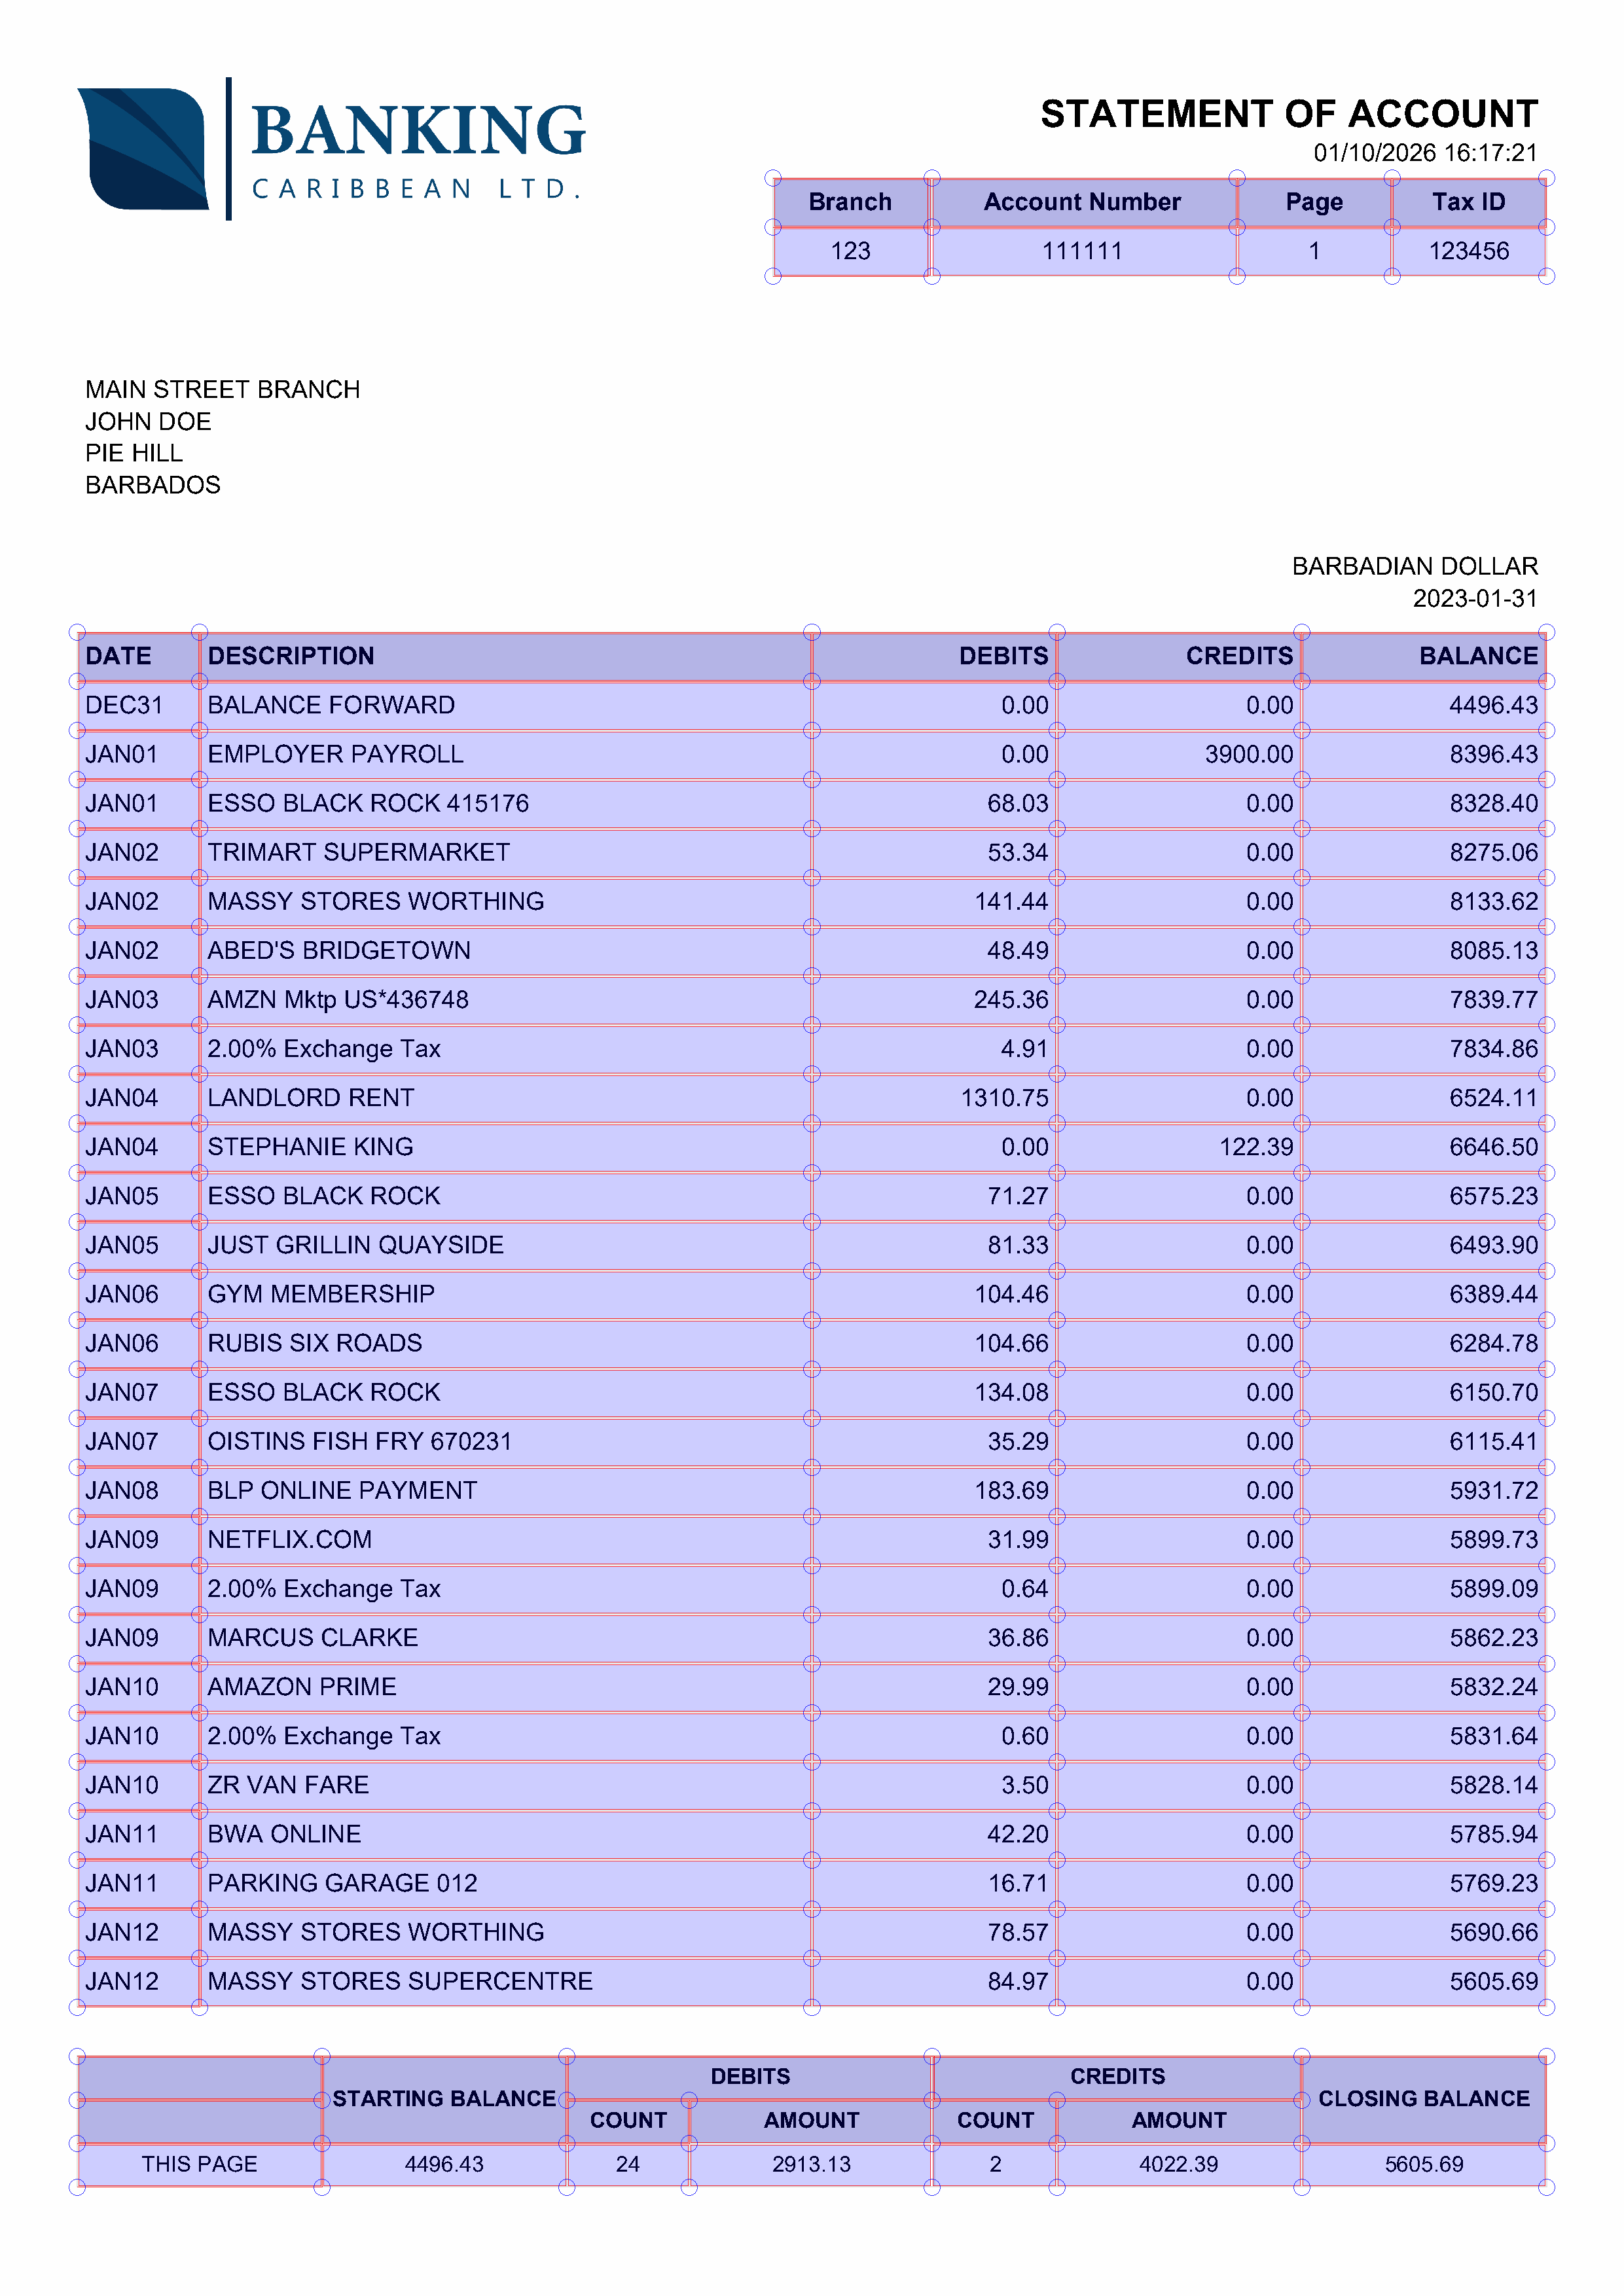

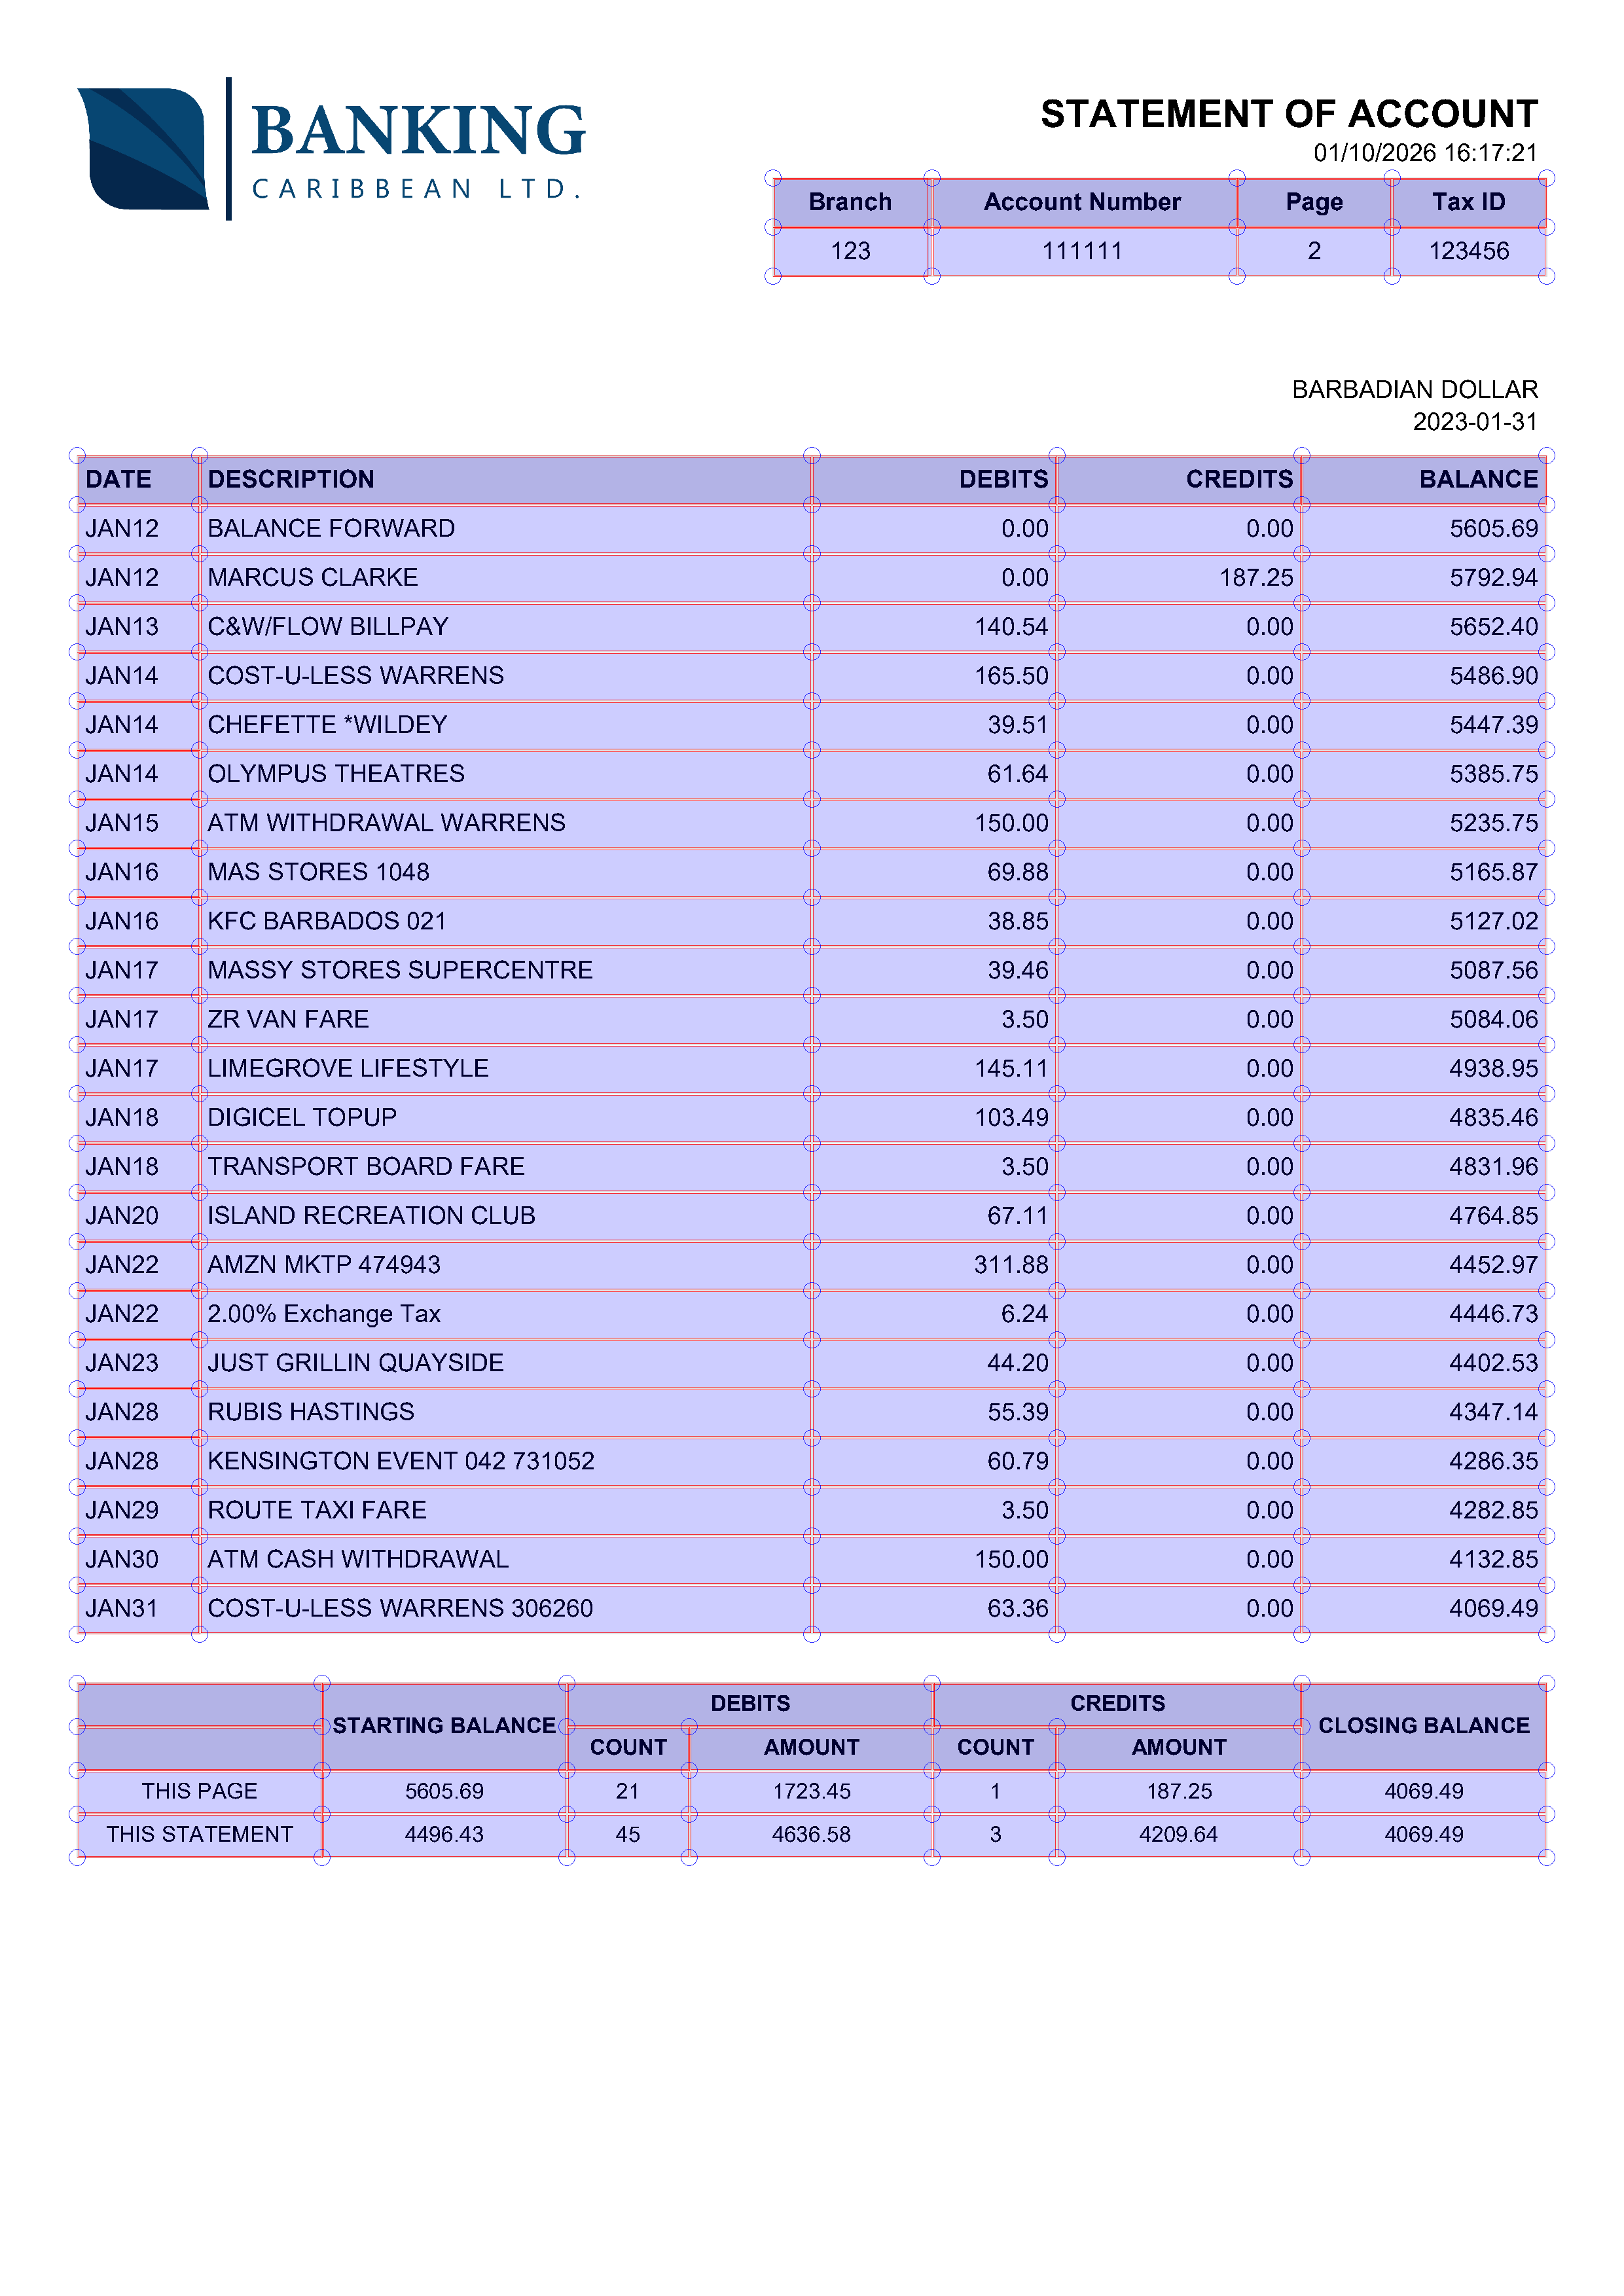

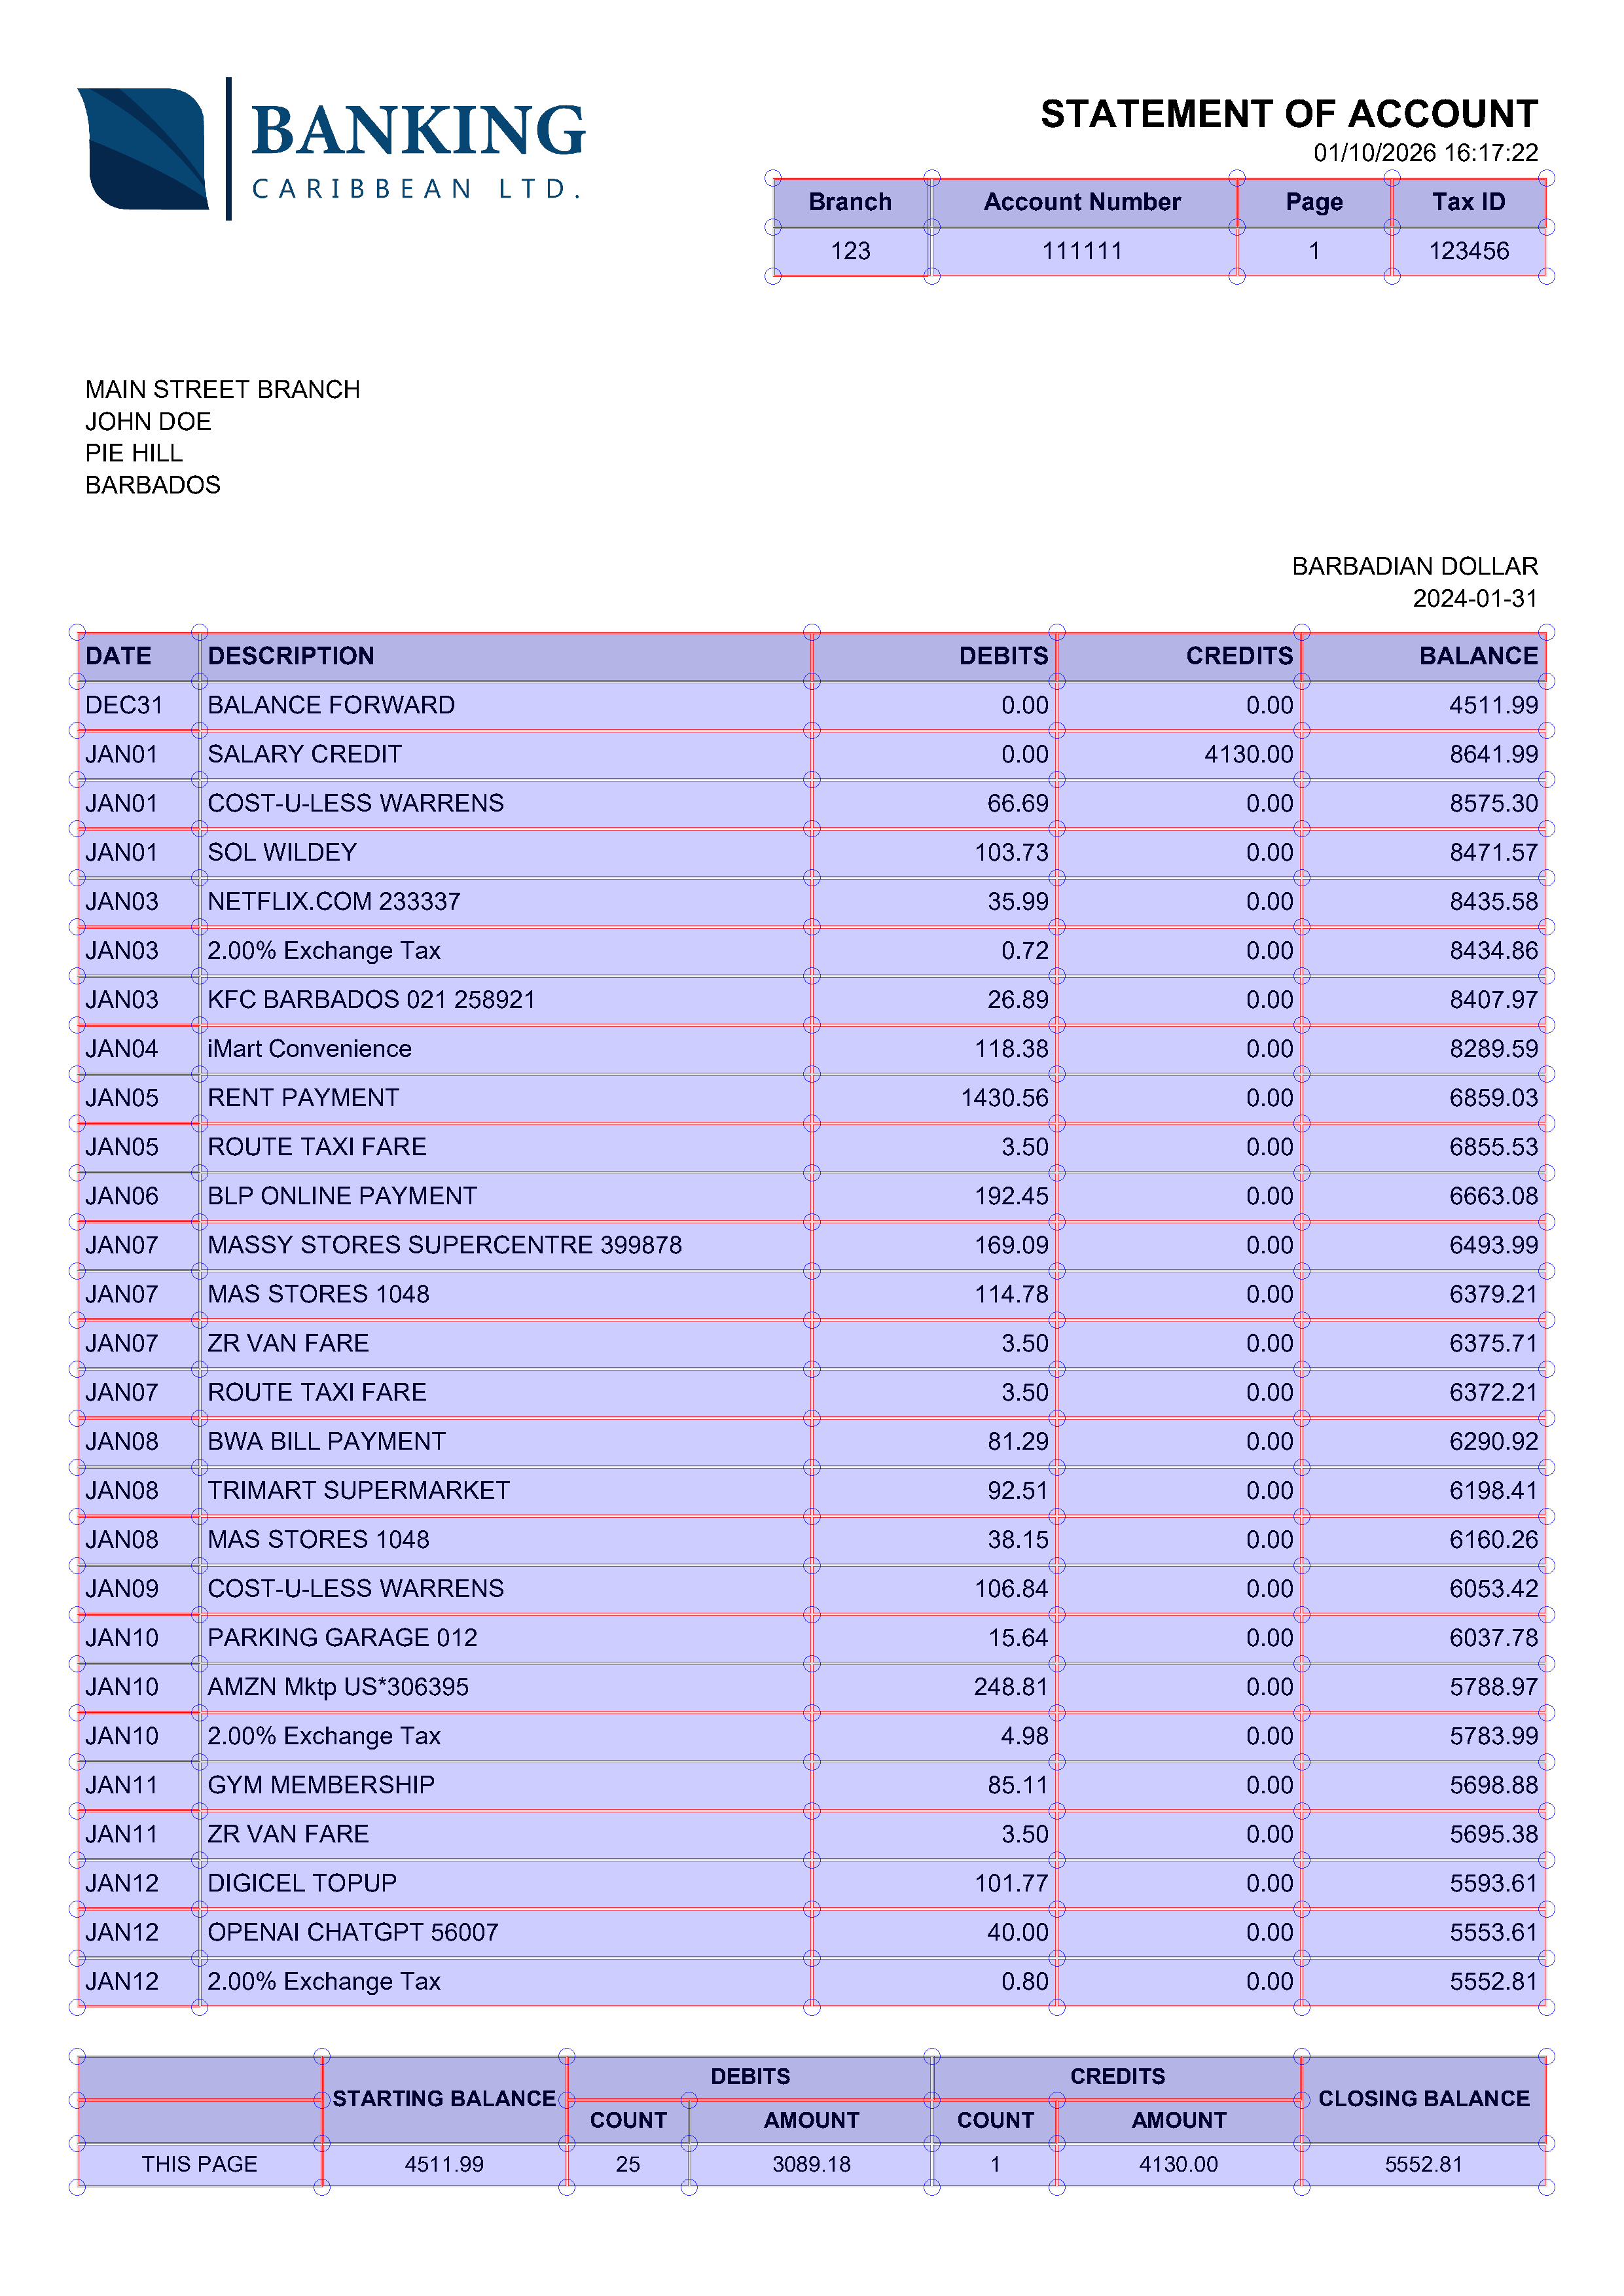

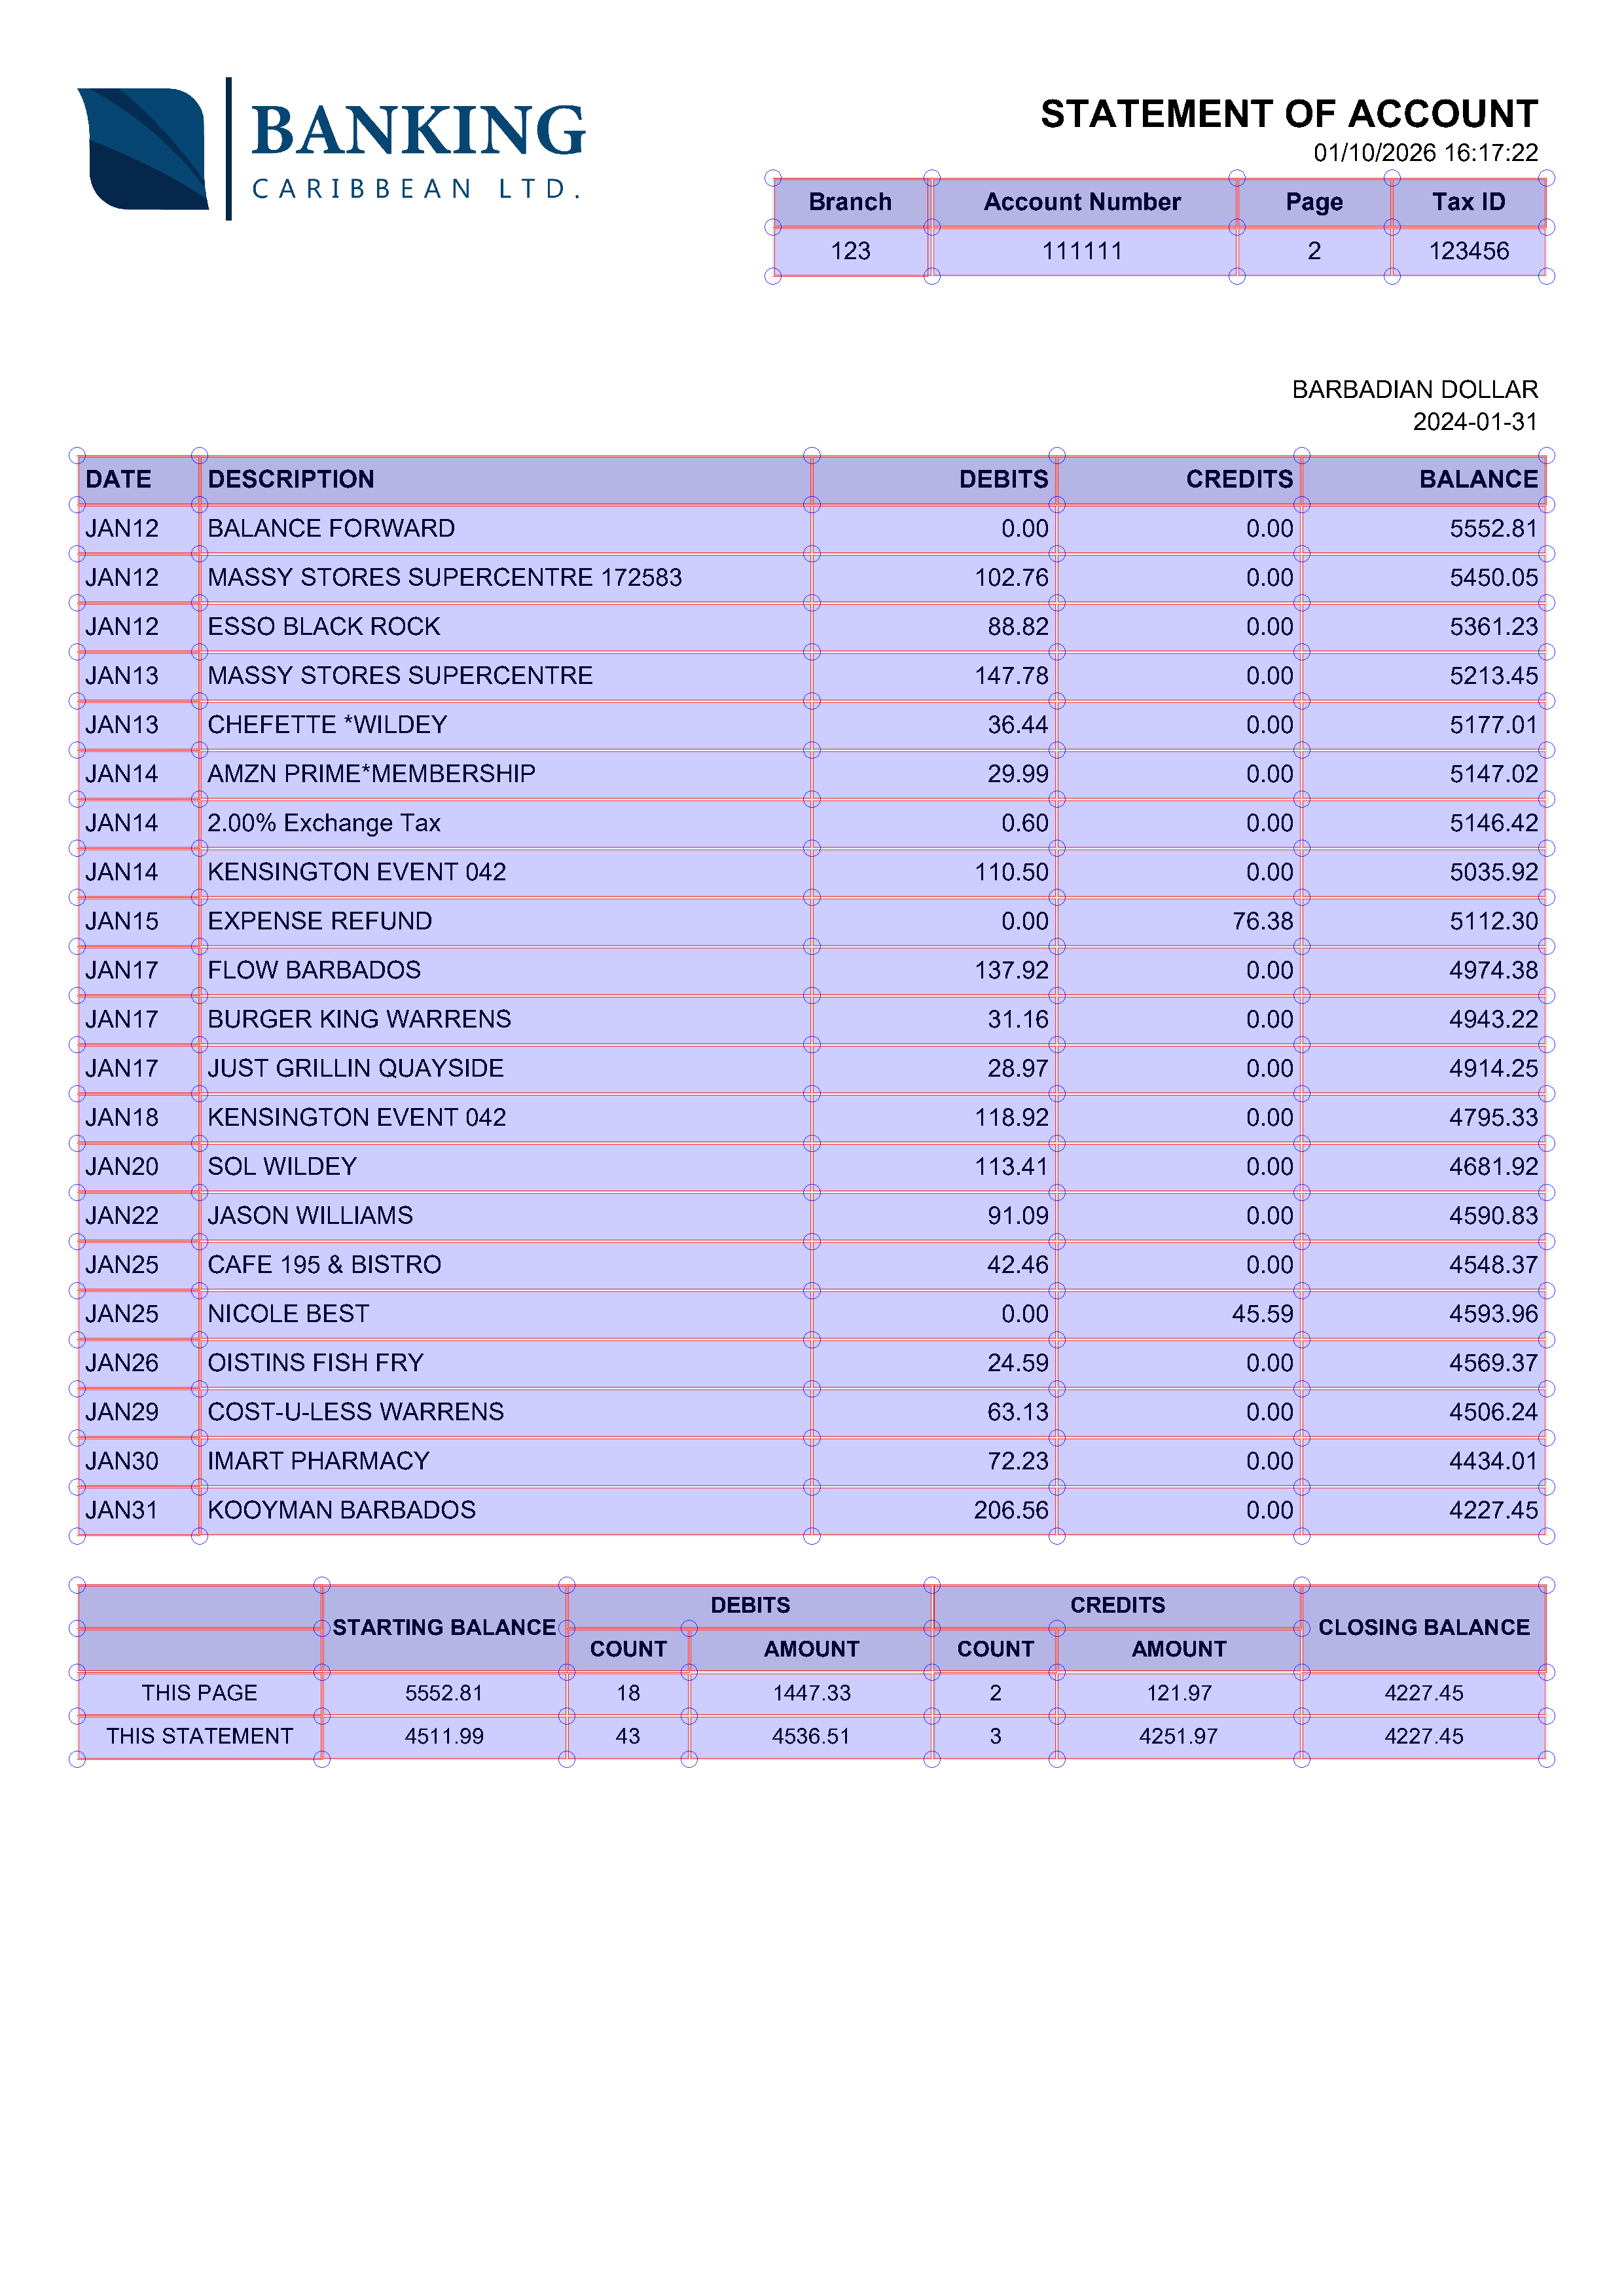

In [289]:
for file in files[:2]: # Use only 2 PDFs
    file_path = f"{dir_path}{file}"
    with pdfplumber.open(file_path) as pdf:
        for pg in pdf.pages:
            im = pg.to_image(resolution=300)
            display(im.debug_tablefinder(table_settings={}))
